# 01 — Semana 8: dataset, splits, preprocesamiento, EDA de fragmentos y Visualizador 1
**Proyecto Integrador Corte 2 — PENGWIN (fracturas pélvicas en CT)**

Este notebook es el **seguimiento del proceso** de la semana 8. No duplica lógica: toda la implementación vive en `src/*.py` y aquí solo se ejecuta, se muestran los resultados y se interpretan.

| Paso | Script / módulo | Salida |
|---|---|---|
| 1. Manifest | `src/build_manifest.py` | `data/manifest.csv` |
| 2. Diagnóstico HU | `src/check_hu_outliers.py` | consola |
| 3. Splits fijos | `src/make_splits.py` | `data/splits.json` |
| 4. Carga y preprocesamiento | `src/pengwin_io.py` (módulo único para entrenamiento, inferencia y visualizadores) | figuras en el notebook |
| 5. EDA de fragmentos | `src/eda_fragments.py` | `data/eda_fragments_detalle.csv`, `outputs/eda/*` |
| 5.1 Fragmento principal y tamaño | `src/eda_fragmento_principal_y_tamano.py` | `data/eda_fragmento_principal_resumen.csv`, `data/eda_fragmentos_individuales.csv`, `outputs/eda/hist_*_fragmento*.png` |
| 6. Visualizador 1 (MIP y reconstrucción 3D) | `src/raw_view.py`, `src/volumen_3d_visualizer.py` | `outputs/figures/volumen_3d_*.html` |

El análisis de intensidades (metal, endurecimiento de haz, desajuste de histograma entre casos) está en `02_eda_intensidades.ipynb`. La normalización final de la imagen que entra al modelo (gamma 1.5) se decidió en la semana 9 y se documenta en `03_semana9_deteccion.ipynb`.

> Uso exclusivamente académico. No es un dispositivo médico ni ha sido validado clínicamente.

## Objetivo

Construir y verificar la base del proyecto antes de entrenar: inventario de los 100 volúmenes,
diagnóstico de los valores HU, splits fijos por paciente, carga y preprocesamiento, EDA de los
fragmentos y el Visualizador 1 sobre el volumen sin procesar.

**Formato de los datos.** El dataset PENGWIN 2024 (Task 1, CT) se distribuye en formato `.mha`
(MetaImage) y no en NIfTI, como menciona el enunciado. El profesor aprobó trabajar con `.mha`. Se
lee con SimpleITK, y su cabecera conserva el espaciado y la orientación, la misma información que
tendría un NIfTI.

In [1]:
# --- Setup: ubicarse en la raíz del repo (los scripts usan rutas relativas data/ y outputs/) ---
%matplotlib inline
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
if "src" not in sys.path:
    sys.path.insert(0, "src")
assert Path("data/raw").exists(), "No encuentro data/raw: descarga PENGWIN de Zenodo y descomprímelo ahí (ver README)."

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

SEED = 42
np.random.seed(SEED)
print("Raíz del repo:", Path.cwd(), "| Python:", sys.executable)

Raíz del repo: /Users/mariavalencia/Downloads/pengwin_semana8 | Python: /Users/mariavalencia/Downloads/pengwin_fixed/.venv/bin/python


## 1. Manifest del dataset
El dataset viene en **`.mha`** (no NIfTI), así que se carga con SimpleITK. El spacing físico (mm/vóxel) se lee del header con `GetSpacing()`.

Si `data/manifest.csv` ya existe se reutiliza; para regenerarlo, borrar el archivo o poner `REGENERAR = True` (tarda ~1 min).

In [2]:
REGENERAR = False
if REGENERAR or not Path("data/manifest.csv").exists():
    %run src/build_manifest.py

manifest = pd.read_csv("data/manifest.csv", dtype={"case_id": str})
print(f"Casos: {len(manifest)} | válidos: {int(manifest['valido'].sum())}")
manifest[["case_id", "shape_z", "shape_y", "shape_x", "spacing_x_mm", "spacing_y_mm", "spacing_z_mm",
          "hu_min", "hu_max", "n_fragmentos_unicos", "valido"]].head(10)

Casos: 100 | válidos: 100


,case_id,shape_z,shape_y,shape_x,spacing_x_mm,spacing_y_mm,spacing_z_mm,hu_min,hu_max,n_fragmentos_unicos,valido
0,001,401,512,512,0.781250,0.781250,0.80000,-1023.0,2775.0,4,True
1,002,337,276,413,0.824219,0.824219,0.80000,-1023.0,4711.0,6,True
2,003,285,381,512,0.759766,0.759766,1.00000,-1023.0,16709.0,6,True
3,004,224,254,386,0.843750,0.843750,1.00000,-1418.0,4961.0,6,True
4,005,312,512,512,0.896484,0.896484,1.00000,-1023.0,4695.0,6,True
5,006,283,279,426,0.812500,0.812500,1.00000,-1023.0,1649.0,7,True
6,007,317,512,512,0.835938,0.835938,1.00000,-1023.0,19380.0,7,True
7,008,335,512,512,0.742188,0.742188,0.80000,-1024.0,1713.0,5,True
8,009,303,245,415,0.812500,0.812500,0.80000,-1023.0,1613.0,5,True
9,010,350,512,512,0.946000,0.946000,0.79895,-2048.0,7573.0,5,True


In [3]:
# Resumen de geometría: tamaño de los volúmenes y spacing
manifest[["shape_z", "shape_y", "shape_x", "spacing_x_mm", "spacing_y_mm", "spacing_z_mm"]].describe().round(3)

,shape_z,shape_y,shape_x,spacing_x_mm,spacing_y_mm,spacing_z_mm
count,100.000,100.00,100.000,100.000,100.000,100.000
mean,321.060,427.67,490.010,0.819,0.819,0.891
std,43.495,116.89,43.316,0.079,0.079,0.109
min,193.000,154.00,322.000,0.658,0.658,0.625
25%,285.750,299.50,508.000,0.781,0.781,0.800
50%,326.000,512.00,512.000,0.798,0.798,0.801
75%,350.000,512.00,512.000,0.858,0.858,1.000
max,414.000,512.00,512.000,1.220,1.220,1.250


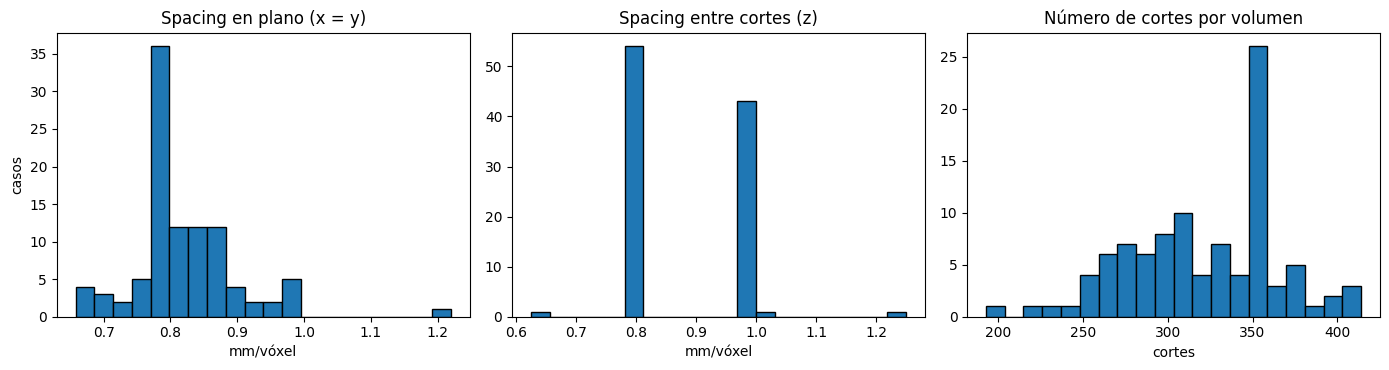

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(manifest["spacing_x_mm"], bins=20, edgecolor="black")
axes[0].set(title="Spacing en plano (x = y)", xlabel="mm/vóxel", ylabel="casos")
axes[1].hist(manifest["spacing_z_mm"], bins=20, edgecolor="black")
axes[1].set(title="Spacing entre cortes (z)", xlabel="mm/vóxel")
axes[2].hist(manifest["shape_z"], bins=20, edgecolor="black")
axes[2].set(title="Número de cortes por volumen", xlabel="cortes")
plt.tight_layout(); plt.show()

**Lectura:** 100/100 casos válidos (imagen + máscara, mismas dimensiones). El spacing **no es uniforme entre casos** (≈0.66–1.22 mm en plano, 0.625–1.25 mm en z), por eso toda medida de distancia o volumen debe usar el spacing propio de cada caso y nunca reportarse en vóxeles.

## 2. Diagnóstico de valores HU
Rango esperado de un CT: aprox. -1000 (aire) a ~3000 HU (hueso cortical denso). Todo lo que se salga de ahí es padding del escáner o metal.

In [5]:
%run src/check_hu_outliers.py

Total casos válidos: 100

Top 5 casos con HU máximo más alto:
 case_id  hu_min  hu_max     hu_mean
      80 -1023.0 47685.0 -600.436101
      68 -6211.0 30445.0 -757.690200
     100 -6152.0 24970.0 -936.068190
      55 -1023.0 23354.0 -668.465611
      84 -1023.0 19419.0 -546.270047

Top 5 casos con HU mínimo más bajo:
 case_id  hu_min  hu_max      hu_mean
      68 -6211.0 30445.0  -757.690200
     100 -6152.0 24970.0  -936.068190
      51 -3376.0  9741.0  -949.747885
      96 -3193.0 13843.0  -708.974439
      74 -2913.0 15467.0 -1004.721474

Casos con valores fuera del rango esperado (-1100 a 5000 HU): 52
 case_id  hu_min  hu_max      hu_mean
       3 -1023.0 16709.0  -427.226756
       4 -1418.0  4961.0  -187.163303
       7 -1023.0 19380.0  -610.517546
      10 -2048.0  7573.0  -909.534589
      11 -2285.0  1677.0  -945.008948
      13 -1023.0 16941.0  -669.545505
      19 -2048.0  1727.0  -813.558878
      20 -2048.0  3321.0  -848.485221
      21 -2048.0  1677.0  -691.015887
     

<Figure size 640x480 with 0 Axes>

**Lectura:** 52 casos se salen del rango típico. No son datos corruptos:
- mínimos exactos y repetidos (-2048, -3024…) = **padding** fuera del campo de reconstrucción;
- máximos muy altos (hasta 47 685 HU) = **metal**. El notebook 02 muestra que casi nunca está en el hueso pélvico: son implantes femorales y objetos externos al paciente (fijadores, elementos sobre la camilla).

**Decisión:** `clip` a **[-1024, 3000] HU** antes de cualquier normalización. El efecto del metal sobre el hueso vecino (endurecimiento de haz) y las diferencias de histograma entre casos se analizan en `02_eda_intensidades.ipynb`.

## 3. Splits fijos
Por `case_id` (nunca por corte: evita *data leakage* entre cortes del mismo paciente), estratificado por número de fragmentos y con semilla 42. El archivo versionado es la fuente de verdad, por eso aquí solo se lee.

In [6]:
with open("data/splits.json") as f:
    splits = json.load(f)
splits = {k: [str(c).zfill(3) for c in splits[k]] for k in ("train", "val", "test")}

# chequeos de integridad
todos = splits["train"] + splits["val"] + splits["test"]
assert len(todos) == len(set(todos)), "Hay casos repetidos entre splits (leakage)"
print({k: len(v) for k, v in splits.items()}, "| total:", len(todos), "| sin solapamiento ✔")

{'train': 70, 'val': 15, 'test': 15} | total: 100 | sin solapamiento ✔


## 4. Carga y preprocesamiento (`pengwin_io.py`)

Toda la carga y el preprocesamiento viven en **un solo módulo**, `src/pengwin_io.py`, que usan por igual el entrenamiento, la inferencia del demo y los visualizadores. Así la imagen que ve el modelo al entrenar es idéntica a la que ve en el dashboard, como pidió el profesor.

| Función | Qué hace | Por qué |
|---|---|---|
| `load_case` | Abre imagen y máscara `.mha` y devuelve el spacing del header | Toda medida en mm usa el spacing propio de cada caso |
| `clip_hu` | Recorta a [−1024, 3000] HU | Neutraliza el padding del escáner y los picos de metal (sección 2) |
| `window_hu` | Ventana ósea C400 / W1800 → [0, 1] | Reparte los grises en el rango del hueso (−500 a 1300 HU) |
| `resize_slice` / `resize_label_slice` | Llevan el corte a 256 px | La imagen se interpola; la máscara va por vecino más cercano para no inventar etiquetas intermedias |
| `bone_mask`, `body_mask`, `clean_bone_mask` | Máscara ósea por umbral de 250 HU sobre HU crudo | Solo para el Visualizador 1 (sección 6), nunca como segmentación |

Las máscaras se calculan **sobre HU crudo, antes del ventaneo**: el umbral de 250 HU solo tiene sentido en esa escala.

**Cambio posterior (semana 9):** tras la asesoría, `window_hu` aplica además una corrección **gamma 1.5** sobre la ventana. Abajo se muestran las dos: la ventana lineal de la semana 8 y la entrada actual al modelo. La justificación del gamma está en `03_semana9_deteccion.ipynb`.

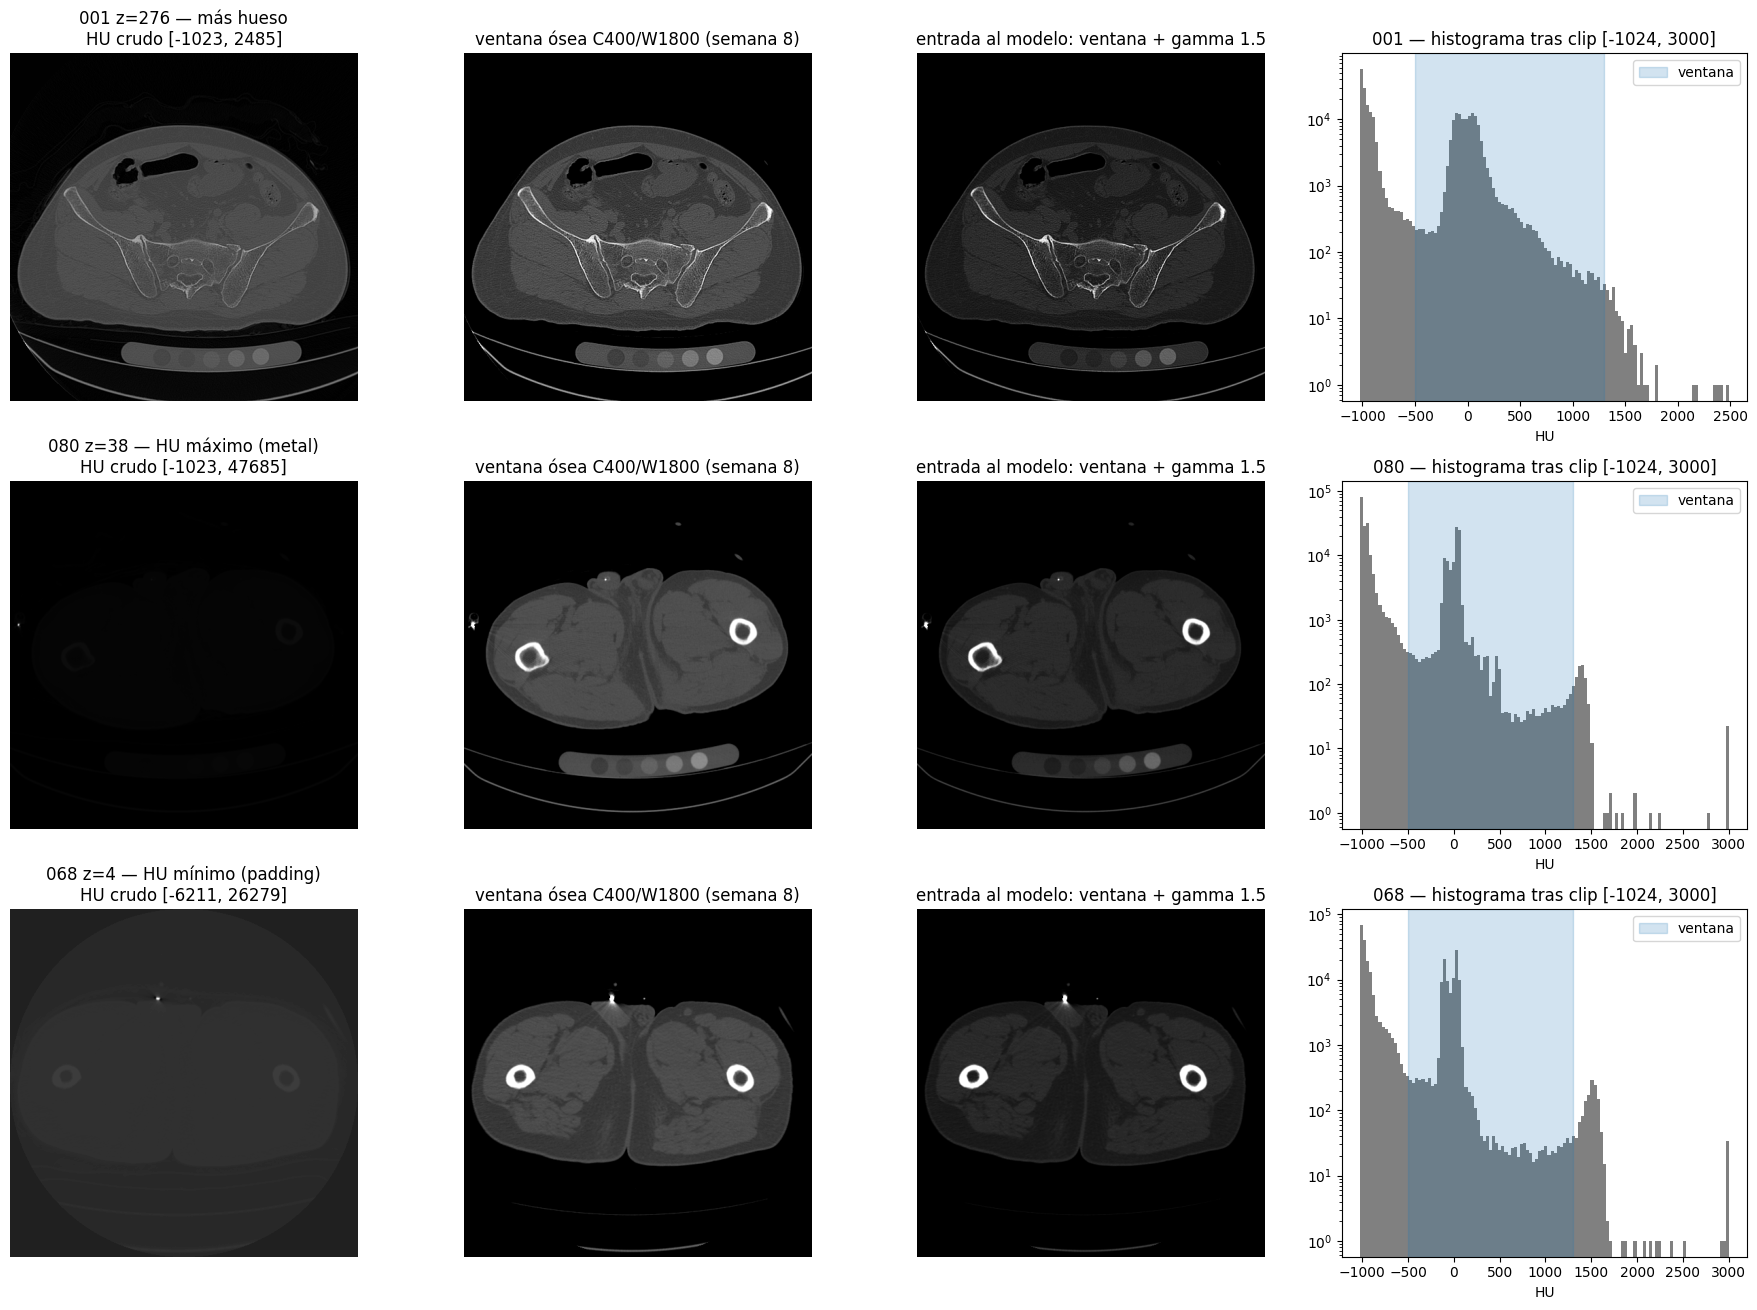

In [7]:
from pengwin_io import load_case, window_hu, clip_hu, CLIP_MIN, CLIP_MAX, WINDOW_CENTER, WINDOW_WIDTH, GAMMA

# Cada caso muestra el corte que ilustra lo suyo:
#   001 normal          -> corte con más hueso etiquetado
#   080 metal extremo   -> corte con el HU máximo del volumen (47 685 HU)
#   068 padding extremo -> corte con el HU mínimo del volumen (-6211 HU)
CRITERIO = {"001": "más hueso", "080": "HU máximo (metal)", "068": "HU mínimo (padding)"}

def elegir_corte(caso, criterio):
    if criterio == "más hueso":
        return int((caso.label > 0).reshape(caso.label.shape[0], -1).sum(axis=1).argmax())
    por_corte = caso.image.reshape(caso.image.shape[0], -1)
    return int(por_corte.max(axis=1).argmax() if "máximo" in criterio else por_corte.min(axis=1).argmin())

fig, axes = plt.subplots(len(CRITERIO), 4, figsize=(18, 4.4 * len(CRITERIO)), squeeze=False)
for i, (cid, criterio) in enumerate(CRITERIO.items()):
    caso = load_case(cid)
    z = elegir_corte(caso, criterio)
    corte = caso.image[z]
    lineal = window_hu(corte, gamma=1.0)     # ventana ósea de la semana 8
    actual = window_hu(corte)                # entrada actual al modelo (gamma por defecto)
    axes[i, 0].imshow(corte, cmap="gray"); axes[i, 0].set_title(f"{cid} z={z} — {criterio}\nHU crudo [{corte.min()}, {corte.max()}]")
    axes[i, 1].imshow(lineal, cmap="gray", vmin=0, vmax=1); axes[i, 1].set_title(f"ventana ósea C{WINDOW_CENTER}/W{WINDOW_WIDTH} (semana 8)")
    axes[i, 2].imshow(actual, cmap="gray", vmin=0, vmax=1); axes[i, 2].set_title(f"entrada al modelo: ventana + gamma {GAMMA}")
    axes[i, 3].hist(clip_hu(corte).ravel(), bins=120, log=True, color="gray")
    axes[i, 3].axvspan(WINDOW_CENTER - WINDOW_WIDTH / 2, WINDOW_CENTER + WINDOW_WIDTH / 2, alpha=0.2, color="tab:blue", label="ventana")
    axes[i, 3].set(title=f"{cid} — histograma tras clip [{CLIP_MIN}, {CLIP_MAX}]", xlabel="HU"); axes[i, 3].legend()
    for a in axes[i, :3]: a.axis("off")
plt.tight_layout(); plt.show()

**Lectura:** el corte del 080 contiene el metal y el del 068 el padding, que en crudo dominan la escala de grises (el metal satura todo lo demás; el padding se ve como el disco gris fuera del campo de reconstrucción). Tras el clip, los dos histogramas quedan dentro de [−1024, 3000] y la ventana ósea los deja con el mismo aspecto que el caso normal: los valores extremos ya no distorsionan la imagen. La ventana concentra los grises donde está el hueso; con gamma 1.5 el tejido blando queda más oscuro y uniforme y el hueso conserva el brillo y la textura interna.

## 5. EDA de fragmentos
Convención oficial de etiquetas: `0` fondo · `1–10` sacro · `11–20` coxal izquierdo · `21–30` coxal derecho.

In [8]:
REGENERAR_EDA = False
if REGENERAR_EDA or not Path("data/eda_fragments_detalle.csv").exists():
    %run src/eda_fragments.py

frag = pd.read_csv("data/eda_fragments_detalle.csv", dtype={"case_id": str})
assert frag["n_labels_desconocidos"].sum() == 0, "Hay labels fuera de la convención oficial"
pd.read_csv("outputs/eda/resumen_estadistico.csv").round(2)

,metrica,valor
0,n_casos,100.00
1,fragmentos_total_min,3.00
2,fragmentos_total_max,9.00
3,fragmentos_total_media,5.75
4,fragmentos_sacro_media,1.53
5,fragmentos_coxal_izq_media,2.15
6,fragmentos_coxal_der_media,2.07
7,casos_sin_fractura_sacro (1 fragmento),55.00
8,casos_sin_fractura_coxal_izq (1 fragmento),34.00
9,casos_sin_fractura_coxal_der (1 fragmento),36.00


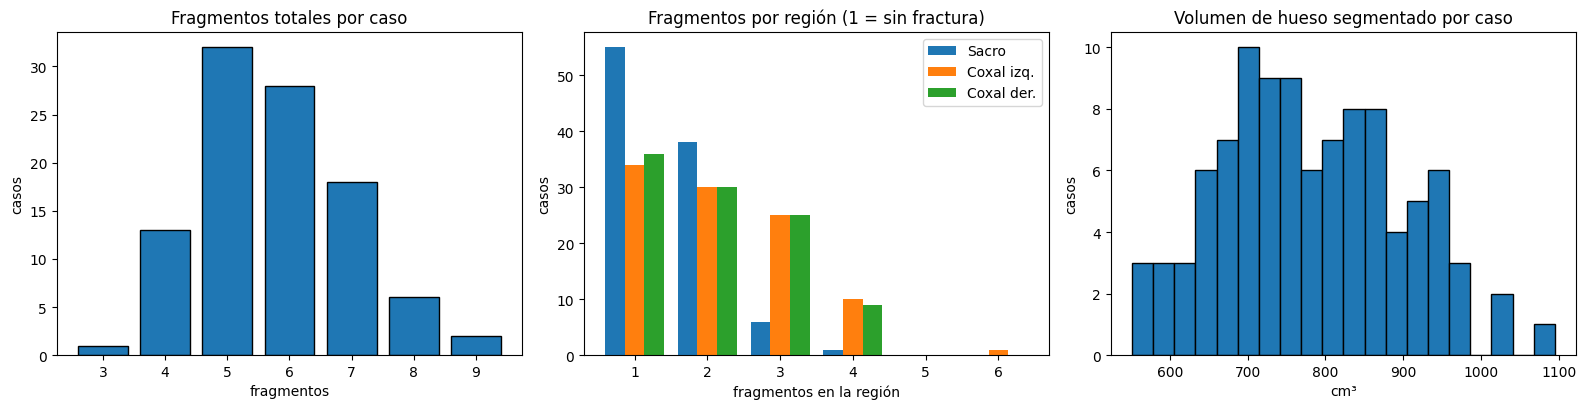

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

vc = frag["n_fragmentos_total"].value_counts().sort_index()
axes[0].bar(vc.index, vc.values, edgecolor="black")
axes[0].set(title="Fragmentos totales por caso", xlabel="fragmentos", ylabel="casos")

cols = {"Sacro": "n_fragmentos_sacro", "Coxal izq.": "n_fragmentos_coxal_izq", "Coxal der.": "n_fragmentos_coxal_der"}
maxf = int(frag[list(cols.values())].max().max())
ancho = 0.27
for j, (nombre, c) in enumerate(cols.items()):
    cuenta = frag[c].value_counts().reindex(range(1, maxf + 1), fill_value=0)
    axes[1].bar(np.arange(1, maxf + 1) + (j - 1) * ancho, cuenta.values, width=ancho, label=nombre)
axes[1].set(title="Fragmentos por región (1 = sin fractura)", xlabel="fragmentos en la región", ylabel="casos"); axes[1].legend()

axes[2].hist(frag["volumen_hueso_total_mm3"] / 1000, bins=20, edgecolor="black")
axes[2].set(title="Volumen de hueso segmentado por caso", xlabel="cm³", ylabel="casos")
plt.tight_layout(); plt.show()

In [10]:
# ¿Quedaron los splits balanceados en dificultad?
frag["split"] = frag["case_id"].map({c: k for k, v in splits.items() for c in v})
frag.groupby("split")[["n_fragmentos_total", "n_fragmentos_sacro", "n_fragmentos_coxal_izq",
                       "n_fragmentos_coxal_der", "volumen_hueso_total_mm3"]].agg(["count", "mean"]).round(2)

n_fragmentos_total       n_fragmentos_sacro        \
                   count  mean              count  mean   
split                                                     
test                  15  5.73                 15  1.47   
train                 70  5.76                 70  1.51   
val                   15  5.73                 15  1.67   

      n_fragmentos_coxal_izq       n_fragmentos_coxal_der       \
                       count  mean                  count mean   
split                                                            
test                      15  2.27                     15  2.0   
train                     70  2.14                     70  2.1   
val                       15  2.07                     15  2.0   

      volumen_hueso_total_mm3             
                        count       mean  
split                                     
test                       15  770475.90  
train                      70  780222.22  
val                        15  795543.01

**Lectura:**
- Las tres regiones aparecen en los 100 casos (mínimo 3 fragmentos = un fragmento por hueso). No habrá clases ausentes a nivel de volumen; el desbalance aparecerá a nivel de **corte**.
- El sacro es el que menos se fractura (55 % intacto, máx. 4 fragmentos); los coxales se fracturan en ~65 % de los casos y son simétricos (2.15 vs 2.07). Máximo observado: 6 fragmentos en una región, holgado frente al límite de 10.
- Splits balanceados: media de fragmentos por caso ≈ 5.76 / 5.73 / 5.73 (train / val / test).
- Limitación: solo hay 1 caso sin ninguna fractura (3 fragmentos) y quedó en train.

### 5.1 Fragmento principal y tamaño de los fragmentos

Dos preguntas que hacía falta responder antes de diseñar el modelo:

1. **¿Cuál es el fragmento principal de cada hueso?** La distancia de separación se mide desde cada fragmento conminuto hasta el fragmento principal de su hueso, pero el dataset no lo marca. La hipótesis es que siempre es la primera etiqueta de la región (1, 11 o 21). Se verifica comparando con el fragmento de mayor volumen real, calculado con el spacing de cada caso.
2. **¿Se pierden fragmentos al bajar a 256 px?** Se mide el volumen en mm³ y cuántos cortes axiales ocupa cada fragmento. Se considera pequeño si ocupa menos de 5 cortes o menos de 500 mm³ (un cubo de unos 8 mm de lado).

In [11]:
REGENERAR_PRINCIPAL = False
if REGENERAR_PRINCIPAL or not Path("data/eda_fragmento_principal_resumen.csv").exists():
    %run src/eda_fragmento_principal_y_tamano.py

resumen = pd.read_csv("data/eda_fragmento_principal_resumen.csv", dtype={"case_id": str})
frags = pd.read_csv("data/eda_fragmentos_individuales.csv", dtype={"case_id": str})

n_ok, n = int(resumen["principal_correcto"].sum()), len(resumen)
pequenos = frags[(frags["n_cortes_axiales"] < 5) | (frags["volumen_mm3"] < 500)]
print(f"Convención 1/11/21 = fragmento de mayor volumen: {n_ok} de {n} combinaciones caso-región ({100 * n_ok / n:.1f} %)")
print(f"Fragmentos analizados: {len(frags)} en {frags['case_id'].nunique()} casos")
print(f"Fragmentos pequeños (<5 cortes o <500 mm³): {len(pequenos)} ({100 * len(pequenos) / len(frags):.1f} %)")
print(f"Cortes axiales por fragmento: mediana {frags['n_cortes_axiales'].median():.0f}, mínimo {frags['n_cortes_axiales'].min()}")
if n_ok < n:
    display(resumen[~resumen["principal_correcto"]])

Convención 1/11/21 = fragmento de mayor volumen: 300 de 300 combinaciones caso-región (100.0 %)
Fragmentos analizados: 575 en 100 casos
Fragmentos pequeños (<5 cortes o <500 mm³): 2 (0.3 %)
Cortes axiales por fragmento: mediana 136, mínimo 9


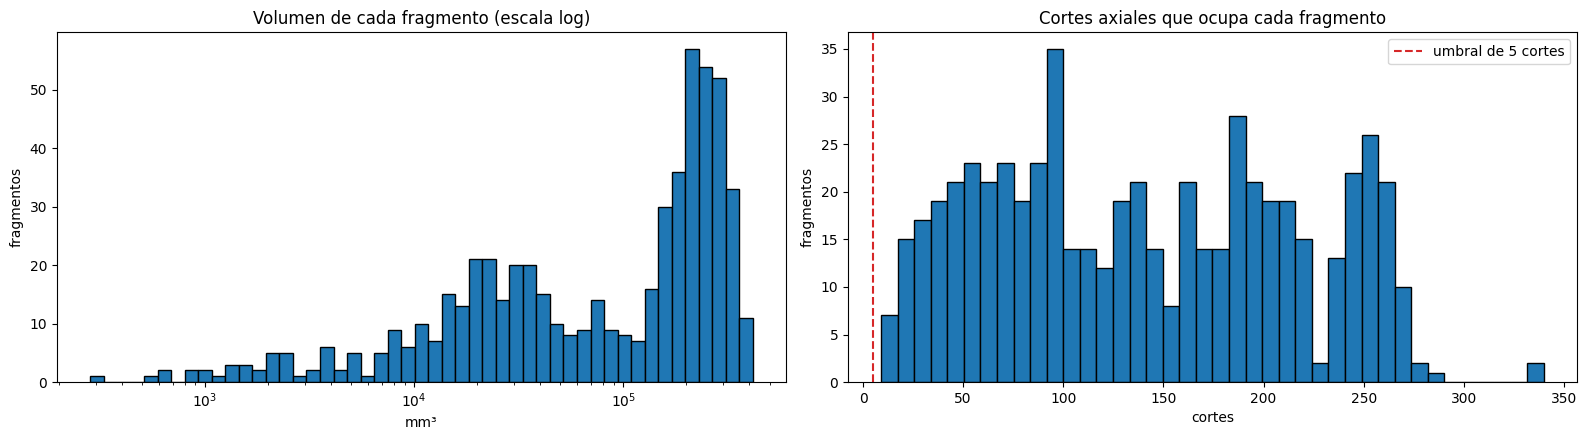

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].hist(frags["volumen_mm3"], bins=np.logspace(np.log10(frags["volumen_mm3"].min()), np.log10(frags["volumen_mm3"].max()), 50), edgecolor="black")
axes[0].set(xscale="log", title="Volumen de cada fragmento (escala log)", xlabel="mm³", ylabel="fragmentos")
axes[1].hist(frags["n_cortes_axiales"], bins=40, edgecolor="black")
axes[1].axvline(5, color="tab:red", ls="--", label="umbral de 5 cortes"); axes[1].legend()
axes[1].set(title="Cortes axiales que ocupa cada fragmento", xlabel="cortes", ylabel="fragmentos")
plt.tight_layout(); plt.show()

**Lectura:**
- La convención se cumple en el **100 %** de las combinaciones caso-región: la etiqueta 1, 11 o 21 es siempre el fragmento de mayor volumen. Se usa directamente como fragmento principal para la distancia de separación, sin calcular el máximo en cada caso.
- El histograma de volumen tiene **dos grupos**: los fragmentos principales, alrededor de 10⁵ mm³, y los conminutos por debajo. Esa separación es la que respalda la convención.
- Solo **2 de 575** fragmentos (0.3 %) son pequeños; el 97 % ocupa más de 20 cortes y el más corto ocupa 9. Trabajar corte a corte a 256 px tiene un riesgo bajo de perder fragmentos, y cada fragmento aporta decenas de cortes de entrenamiento.

## 6. Visualizador 1 — reconstrucción 3D del volumen crudo

Lo que pide el enunciado: reconstrucción 3D del volumen original **mostrando únicamente el hueso**, sin intervención del modelo. Reemplaza al MIP de proyecciones estáticas de la primera versión (`mip_visualizer.py`, eliminado).

La máscara sale de `pengwin_io.clean_bone_mask`, sobre HU crudo:

1. **Umbral óseo** de 250 HU.
2. **Silueta del cuerpo:** componente conectado más grande de HU > −300 con los huecos rellenos. La camilla y los cables quedan fuera porque están separados del cuerpo por aire, aunque tengan HU de hueso.
3. **Descarte de motas** pequeñas dentro del cuerpo (artefactos de metal).
4. **Filtro de profundidad:** los componentes pequeños a menos de 10 mm de la piel (cinturones, electrodos, cables pegados al cuerpo) se descartan; un fragmento real queda rodeado de tejido blando.

**Qué se probó y se descartó:**
- *Apertura morfológica:* la cortical tiene 2–3 vóxeles de grosor, igual que los artefactos, y la erosión borraba hueso real.
- *Recuperación de hueso tenue* (histéresis 150–250 HU con cierre morfológico): subía la cobertura del hueso etiquetado de 57 % a 92 %, pero el cierre puede **sellar líneas de fractura**, que es justo lo que el proyecto debe mostrar. Desde la asesoría de la semana 9 está desactivada por defecto. Costo aceptado: el hueso trabecular de baja densidad puede verse hueco.

La malla 3D se genera con *marching cubes* y se guarda como HTML interactivo de Plotly.

In [13]:
# Genera outputs/figures/volumen_3d_{caso}.html (abrir en el navegador para rotar y hacer zoom)
%run src/volumen_3d_visualizer.py 001 025 068

Caso 001: 2,259,652 voxeles > 250 HU en todo el volumen -> 1,340,208 en la mascara final
Guardado: outputs/figures/volumen_3d_001.html
Caso 025: 764,807 voxeles > 250 HU en todo el volumen -> 642,206 en la mascara final
Guardado: outputs/figures/volumen_3d_025.html
Caso 068: 2,105,356 voxeles > 250 HU en todo el volumen -> 1,917,177 en la mascara final
Guardado: outputs/figures/volumen_3d_068.html


<Figure size 640x480 with 0 Axes>

Las reconstrucciones interactivas quedan en `outputs/figures/volumen_3d_001.html`, `volumen_3d_025.html` y `volumen_3d_068.html`. Como un HTML interactivo no se puede guardar dentro del notebook, abajo se muestra el efecto de la limpieza en proyecciones estáticas: a la izquierda el umbral de 250 HU solo, a la derecha la máscara limpia que usa el visualizador.

001:  2,259,652 vóxeles > 250 HU ->  1,340,208 en la máscara limpia (59 %)
025:    764,807 vóxeles > 250 HU ->    642,206 en la máscara limpia (84 %)
068:  2,105,356 vóxeles > 250 HU ->  1,917,177 en la máscara limpia (91 %)


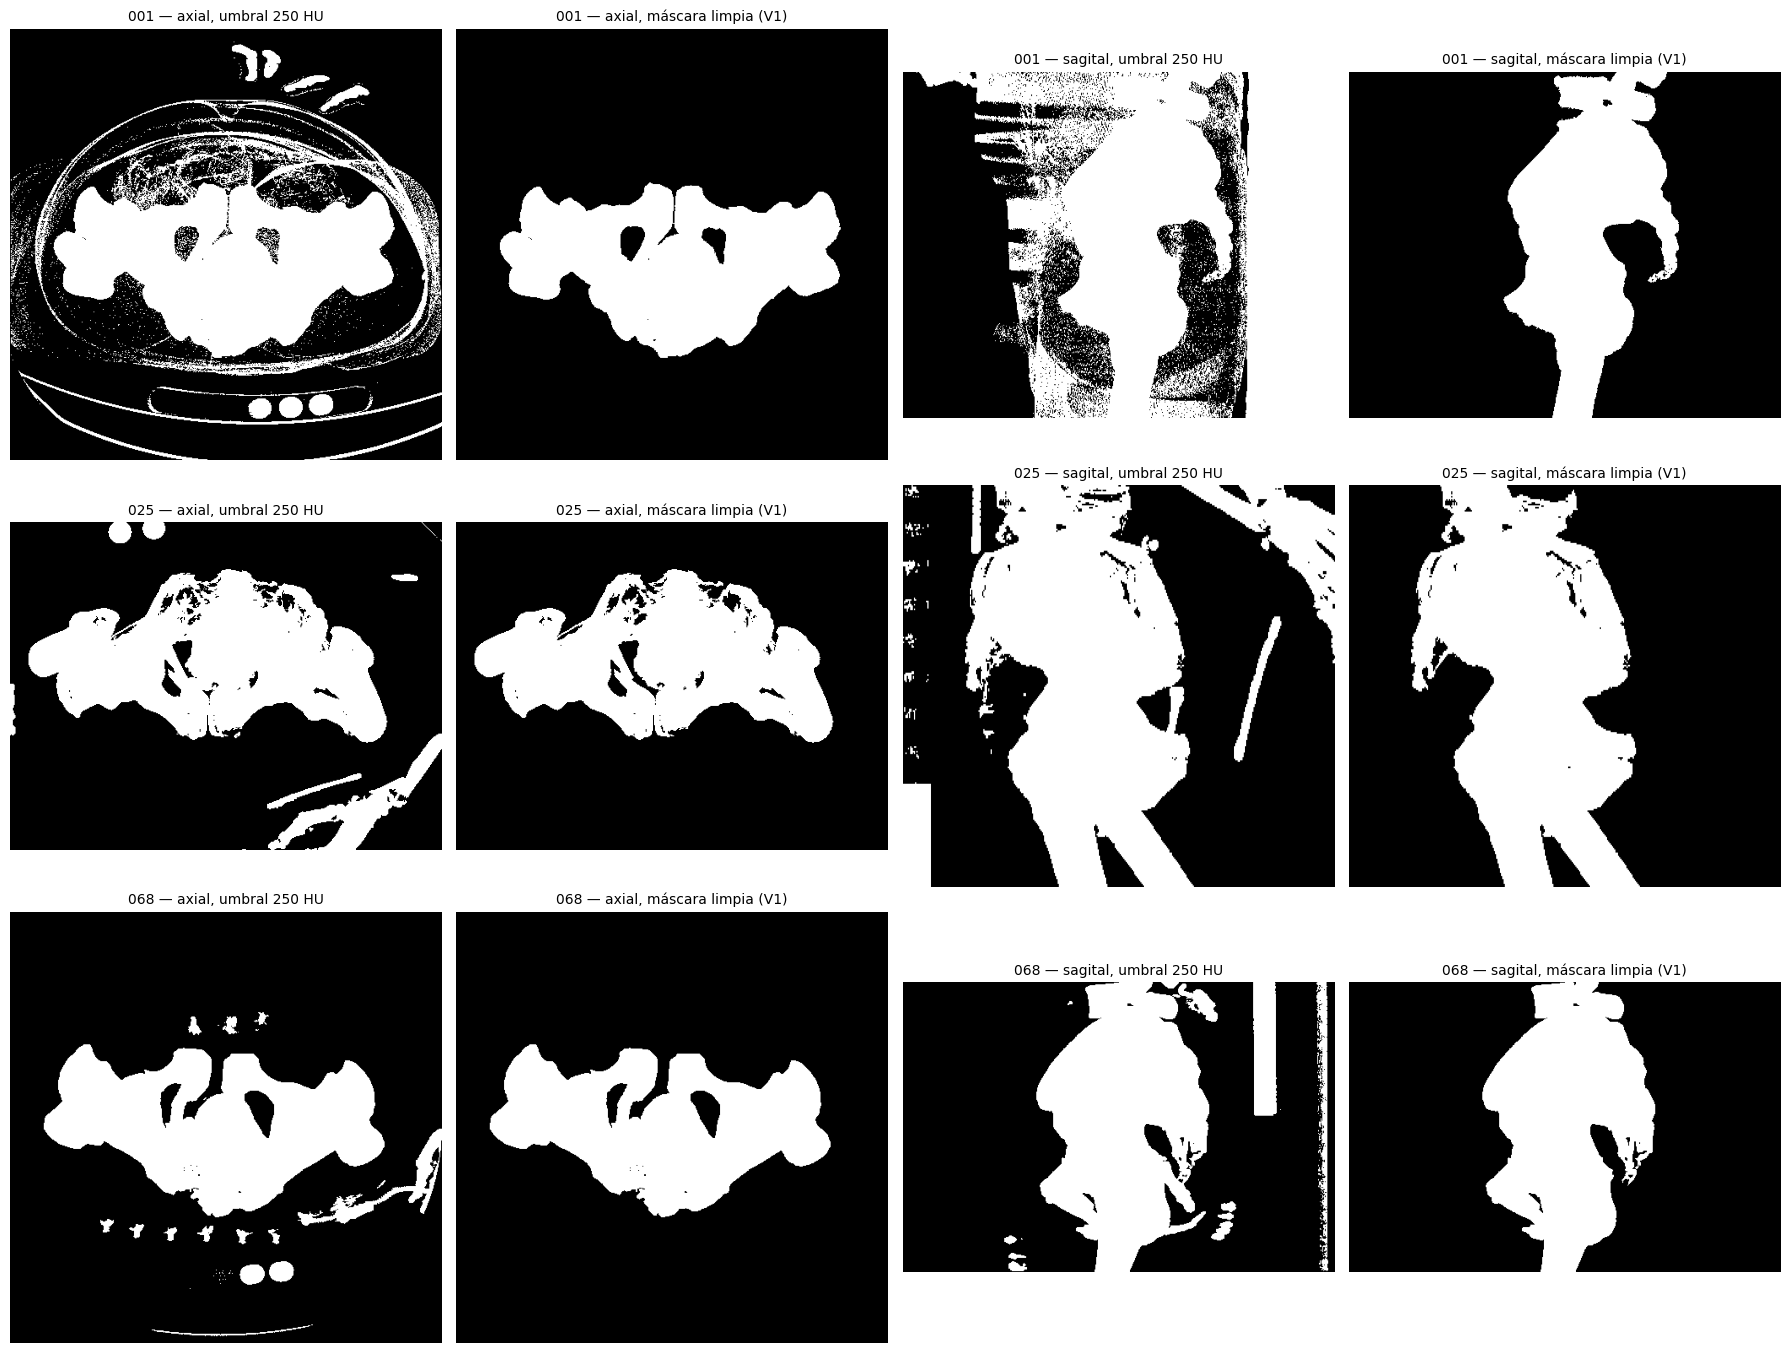

In [14]:
from pengwin_io import bone_mask, clean_bone_mask

VISTAS = [("axial", 0), ("sagital", 2)]
CASOS_V1 = ["001", "025", "068"]
fig, axes = plt.subplots(len(CASOS_V1), 4, figsize=(18, 4.6 * len(CASOS_V1)), squeeze=False)
for i, cid in enumerate(CASOS_V1):
    caso = load_case(cid, load_label=False)
    sx, sy, sz = caso.spacing_xyz                       # SimpleITK: (x, y, z) en mm
    cruda = bone_mask(caso.image)
    limpia = clean_bone_mask(caso.image, spacing_zyx=(sz, sy, sx))
    print(f"{cid}: {int(cruda.sum()):>10,} vóxeles > 250 HU -> {int(limpia.sum()):>10,} en la máscara limpia "
          f"({100 * limpia.sum() / cruda.sum():.0f} %)")
    j = 0
    for nombre, eje in VISTAS:
        aspecto = (sy / sx) if eje == 0 else (sz / sy)
        for etiqueta, m in (("umbral 250 HU", cruda), ("máscara limpia (V1)", limpia)):
            ax = axes[i, j]; j += 1
            ax.imshow(m.max(axis=eje), cmap="gray", aspect=aspecto, origin="upper" if eje == 0 else "lower")
            ax.set_title(f"{cid} — {nombre}, {etiqueta}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()

**Lectura:** el umbral de 250 HU por sí solo captura mucho más que hueso. Además de la camilla (los arcos bajo el cuerpo en la vista axial y las líneas verticales en la sagital) aparecen el maniquí de calibración que va bajo el paciente (los círculos de los casos 001 y 068), una fila de electrodos o un cinturón sobre la piel (068), una barra externa larga (025) y la piel moteada por el ruido (001). En la máscara limpia todo eso desaparece y la pelvis queda completa.

La fracción de vóxeles que sobrevive (59 % en el 001, 84 % en el 025 y 91 % en el 068) depende de cuánto objeto externo tenía cada estudio, no de hueso perdido. En el caso 025 el hueso trabecular se ve incompleto en algunas zonas: es el costo de no usar la recuperación de hueso tenue, documentado arriba.

### 6.1 MIP del hueso en los tres ejes (`src/raw_view.py`)

El enunciado (sección 3.4) pide una proyección de máxima intensidad que muestre solo el hueso, con
un umbral en HU sobre el volumen sin procesar. `compute_mips` toma, en cada línea que atraviesa el
volumen, el vóxel de mayor HU dentro de `clean_bone_mask` (250 HU más la limpieza de camilla y
cables) y remuestrea a 1 mm por píxel. No interviene ningún modelo.

Se muestran un caso con orientación estándar y uno de los 34 que la cabecera trae girados 180° en
el plano (`TransformMatrix -1 0 0 0 -1 0 0 0 1`). El MIP es crudo, así que el giro se ve tal cual:
es el problema que la orientación canónica corrige en el modelo final.

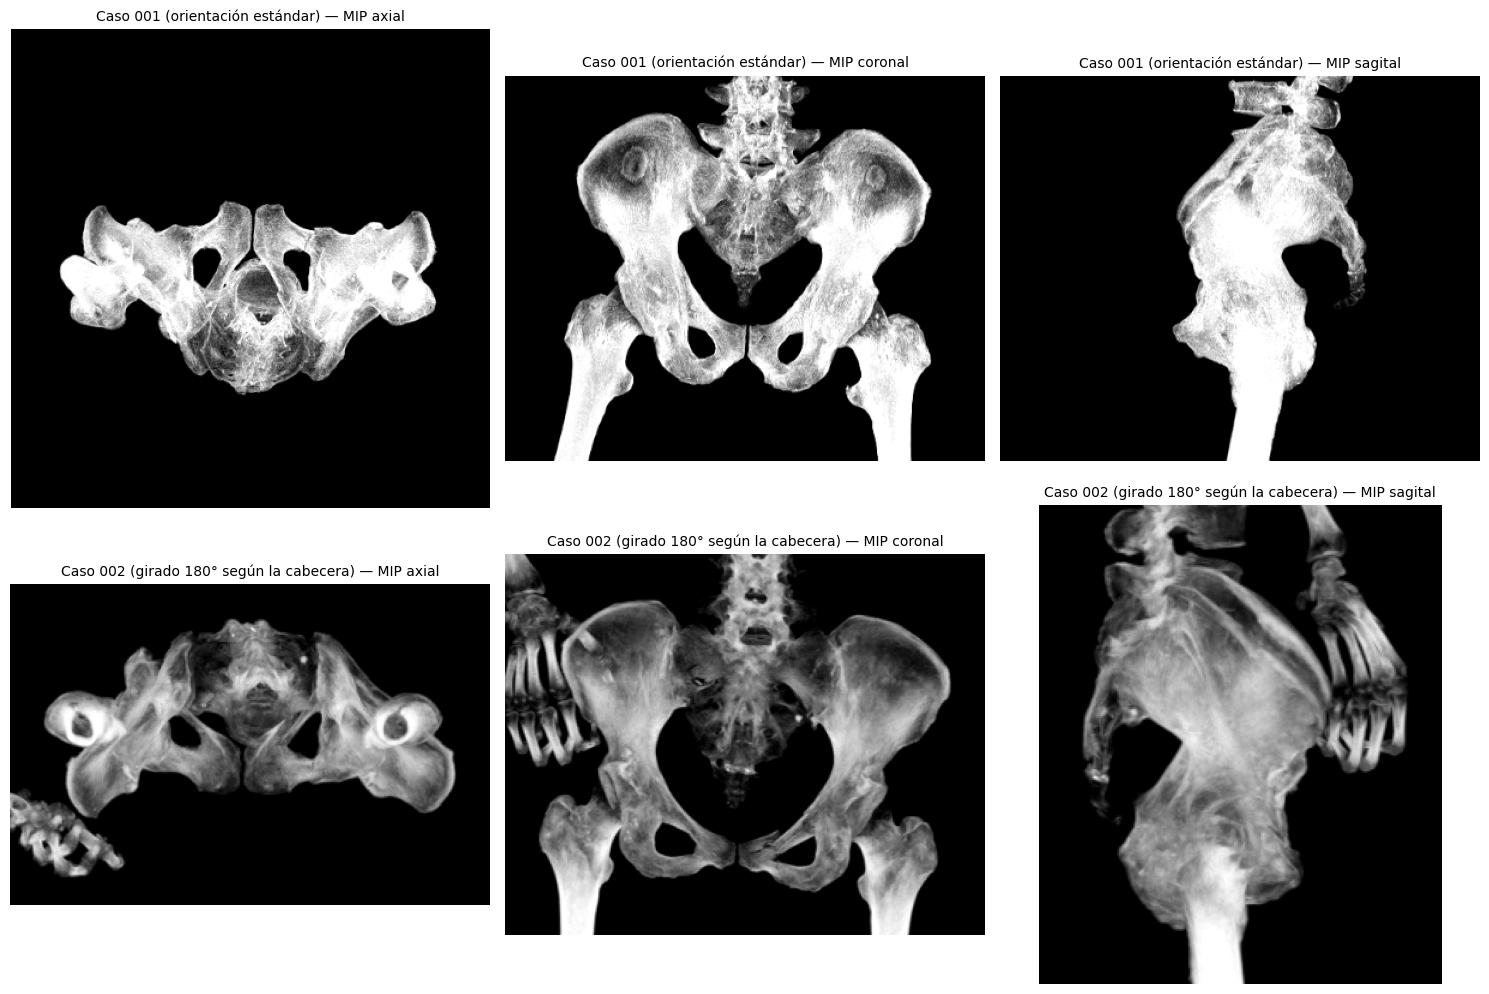

In [15]:
import os, sys
from pathlib import Path
import matplotlib.pyplot as plt

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "raw_view.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))
from pengwin_io import load_case
from raw_view import bone_mask_for, compute_mips
from orientacion import is_rotated

ids = [f"{i:03d}" for i in range(1, 101)]
normal = next(c for c in ids if not is_rotated(c))
girado = next(c for c in ids if is_rotated(c))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for fila, cid in enumerate([normal, girado]):
    caso = load_case(cid, load_label=False)
    mascara = bone_mask_for(caso.image, caso.spacing_xyz)
    mips = compute_mips(caso.image, mascara, caso.spacing_xyz)
    etiqueta = "girado 180° según la cabecera" if fila else "orientación estándar"
    for ax, vista in zip(axes[fila], ["axial", "coronal", "sagital"]):
        ax.imshow(mips[vista], cmap="gray")
        ax.set_title(f"Caso {cid} ({etiqueta}) — MIP {vista}", fontsize=10)
        ax.axis("off")
fig.tight_layout()
Path("outputs/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("outputs/figures/mip_visualizador1.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Estado de la semana 8
- [x] Dataset curado con splits fijos (70 / 15 / 15, por paciente, semilla 42, reproducibles)
- [x] Carga `.mha` + ventaneo HU con clip, centralizados en `pengwin_io.py`
- [x] EDA de fragmentos por caso
- [x] Validación del fragmento principal (100 %) y tamaño de fragmentos (0.3 % pequeños)
- [x] Visualizador 1: MIP en los tres ejes (`raw_view.py`) y reconstrucción 3D interactiva, limpios de camilla y cables
- [x] EDA de intensidades (endurecimiento de haz y desajuste de histograma) → `02_eda_intensidades.ipynb`

**Cambios posteriores a la semana 8, ya incorporados en el código:**
- `window_hu` aplica gamma 1.5 en lugar de CLAHE (asesoría de la semana 9) → `03_semana9_deteccion.ipynb`.
- La recuperación de hueso tenue del Visualizador 1 quedó desactivada por defecto (riesgo de sellar líneas de fractura).

## 8. Conclusiones

- **Dataset completo y heterogéneo.** Los 100 CT tienen su máscara. El número de cortes axiales
  tiene una mediana de 326 (máximo 414), y el espaciado varía entre casos (en el plano, mediana
  0.80 mm y hasta 1.22 mm; entre cortes, hasta 1.25 mm). Por eso las distancias se reportan en mm
  y no en píxeles.
- **Splits comparables.** La partición 70/15/15 por paciente no tiene solapamiento, y el volumen
  óseo medio es parecido en los tres splits (770 476, 780 222 y 795 543 mm³ en test, train y val).
- **Convención de etiquetas verificada.** El ID 1/11/21 corresponde al fragmento de mayor volumen
  en las 300 combinaciones caso-región. El primario está bien definido y los errores del modelo no
  vienen de etiquetas inconsistentes.
- **Los fragmentos son visibles para un modelo 2D.** De 575 fragmentos, solo 2 (0.3 %) son
  pequeños (menos de 5 cortes o 500 mm³). La mediana es de 136 cortes axiales por fragmento y el
  mínimo es 9.
- **Visualizador 1 cumplido.** MIP en los tres ejes y reconstrucción 3D, solo del hueso, sobre HU
  crudo. El umbral de 250 HU sirve para visualizar, no para segmentar (ver notebook 02).
- **Hallazgo posterior.** En la Semana 10 se encontró que 34 de los 100 volúmenes vienen girados
  180° en el plano según la cabecera. La corrección (orientación canónica) es parte del modelo
  final H6.